# EDA 2 — Users: activity, histories, cold start and history-based signals

Training split only, except where
validation and test are needed to count new users. Inputs are the processed files from `1_Data_Preparation/`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import polars as pl  # only for the 70 M-row candidate table; everything small is pandas
import seaborn as sns

# Project root = folder that contains 1_Data_Preparation/processed (run 1_Data_Preparation/clean_and_validate_data.ipynb first)
try:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path(os.environ.get("NEWSREC_ROOT", "/content/drive/MyDrive/BT4222")).expanduser().resolve()
except ImportError:
    ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / "1_Data_Preparation" / "processed").exists())
PROCESSED = ROOT / "1_Data_Preparation" / "processed"
FIG_DIR = ROOT / "2_EDA" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", palette=["#2a78d6", "#eb6834", "#1baf7a", "#eda100"])
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
print("Project root:", ROOT)

Project root: /Users/anhminhhoang/BT4222


In [2]:
imp = pl.read_parquet(PROCESSED / "impressions_train.parquet", columns=["impression_uid", "user_code", "timestamp", "history_len", "slate_len", "n_clicks"])
cand = pl.read_parquet(PROCESSED / "candidates_train.parquet", columns=["impression_uid", "user_code", "timestamp", "news_code", "clicked"])
news = pl.read_parquet(PROCESSED / "news_catalogue.parquet", columns=["news_code", "category", "exposures_train"])
cat_map = news.select("news_code", pl.col("category").cast(pl.Categorical))

n_imp, n_users, n_exp, n_clicks = len(imp), imp["user_code"].n_unique(), len(cand), int(cand["clicked"].sum())
print("Impressions:", n_imp, "| Users:", n_users, "| Exposures:", n_exp, "| Clicks:", n_clicks)

Impressions: 1897835 | Users: 667880 | Exposures: 70314387 | Clicks: 2868998


# 1. User activity and history length

* **Sparsity**: the median user has **2 impressions** in the 5.3-day window and 37% appear only once.
* The supplied history (clicks before the window) has a median of **11 articles per user** (19 per impression, because active users carry
  longer histories), p95 64, maximum 801; 1.8% of users have none.
* Beyond the shortest histories, clicks per visit rise with history length (history length proxies general engagement).

**Model Implications**
* A history cap of 50 keeps 92% of users' histories complete. In-window behaviour is thin, so user representations must lean on the
  supplied history and on content, not on in-window sequences alone.

Impressions per user:
count    667880.00
mean          2.84
std           2.64
min           1.00
25%           1.00
50%           2.00
75%           3.00
max         104.00
Name: impressions, dtype: float64

Users with 1 impression: 36.6% | active on 2+ days: 54.5%

History length per user:
count    667880.0
mean         19.3
std          24.8
min           0.0
50%          11.0
95%          64.0
max         801.0
Name: history_len, dtype: float64
Users with no history: 1.77% | with > 50: 7.9%

Clicks per impression by history length:
              users  impressions  clicks  clicks_per_impression
history_len                                                    
0             11836        37121   56183                  1.514
1-5          155059       281171  355576                  1.265
6-10         155407       293504  386126                  1.316
11-20        154533       380817  530198                  1.392
21-50        138044       525346  807853                  1.538
51-100    

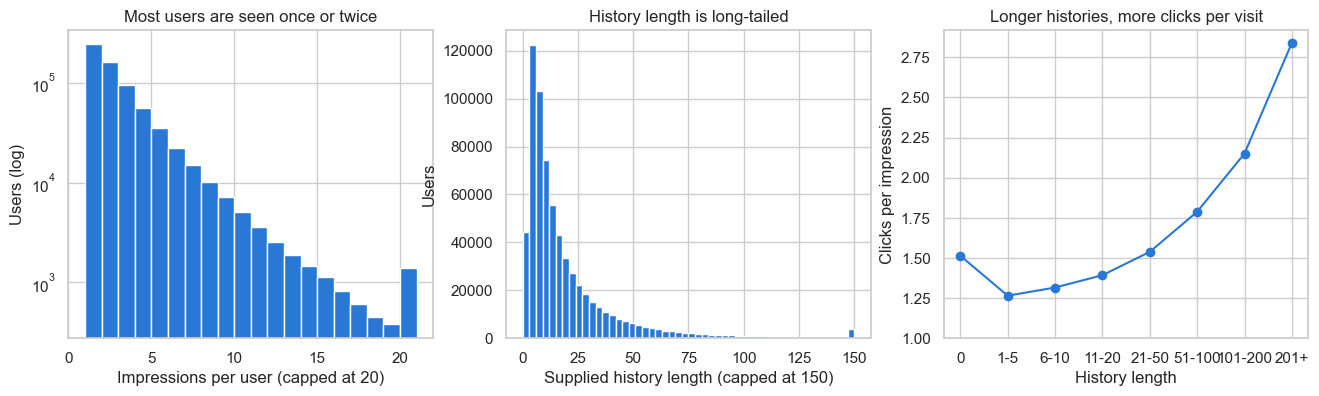

In [3]:
users = (imp.group_by("user_code").agg(impressions=pl.len(), clicks=pl.col("n_clicks").sum(), exposures=pl.col("slate_len").sum(),
                                      days=pl.col("timestamp").dt.date().n_unique(), history_len=pl.col("history_len").first()).to_pandas())
print("Impressions per user:")
print(users.impressions.describe().round(2))
print(f"\nUsers with 1 impression: {100 * (users.impressions == 1).mean():.1f}% | active on 2+ days: {100 * (users.days >= 2).mean():.1f}%")
print("\nHistory length per user:")
print(users.history_len.describe(percentiles=[.5, .95]).round(1))
print(f"Users with no history: {100 * (users.history_len == 0).mean():.2f}% | with > 50: {100 * (users.history_len > 50).mean():.1f}%")

bins = pd.cut(users.history_len, [-1, 0, 5, 10, 20, 50, 100, 200, 10_000], labels=["0", "1-5", "6-10", "11-20", "21-50", "51-100", "101-200", "201+"])
by_hist = users.groupby(bins, observed=True).agg(users=("impressions", "size"), impressions=("impressions", "sum"), clicks=("clicks", "sum"))
by_hist["clicks_per_impression"] = by_hist.clicks / by_hist.impressions
print("\nClicks per impression by history length:")
print(by_hist.round(3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(users.impressions.clip(upper=20), bins=range(1, 22), log=True)
ax[0].set(xlabel="Impressions per user (capped at 20)", ylabel="Users (log)", title="Most users are seen once or twice")
ax[1].hist(users.history_len.clip(upper=150), bins=50)
ax[1].set(xlabel="Supplied history length (capped at 150)", ylabel="Users", title="History length is long-tailed")
ax[2].plot(by_hist.index.astype(str), by_hist.clicks_per_impression, marker="o")
ax[2].set(ylim=(1, None), xlabel="History length", ylabel="Clicks per impression", title="Longer histories, more clicks per visit")
plt.savefig(FIG_DIR / "usr_01_activity_history.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. Cold-start users

Two kinds of cold start exist: users with **no supplied history** (2% of impressions) and users who appear in validation or test but
**never in train**.
* Users without history click exactly as much per visit as the others (1.51).
* **18.4% of validation users and 19.8% of test users are new** relative to train. They still carry a history, though a shorter one
  (median 7 against 23 for returning users), and click somewhat less per visit (1.39 against 1.55).

**Model Implications**
* Build user profiles from the supplied history plus content, which exist for new users; a user-id embedding would be undefined for a fifth
  of test users. Users with no history need an explicit fallback (popularity, freshness, category priors).

 no_history  impressions  clicks_per_impression
      False      1860714                  1.512
       True        37121                  1.514

Users in validation / test by whether they appear in train:
 new_user  users  impressions  median_history  clicks_per_impression      split  user_share
    False 205303       312424            23.0                   1.55       test       80.20
     True  50687        64047             7.0                   1.39       test       19.80
    False 192621       282210            23.0                   1.56 validation       81.63
     True  43342        52703             8.0                   1.41 validation       18.37


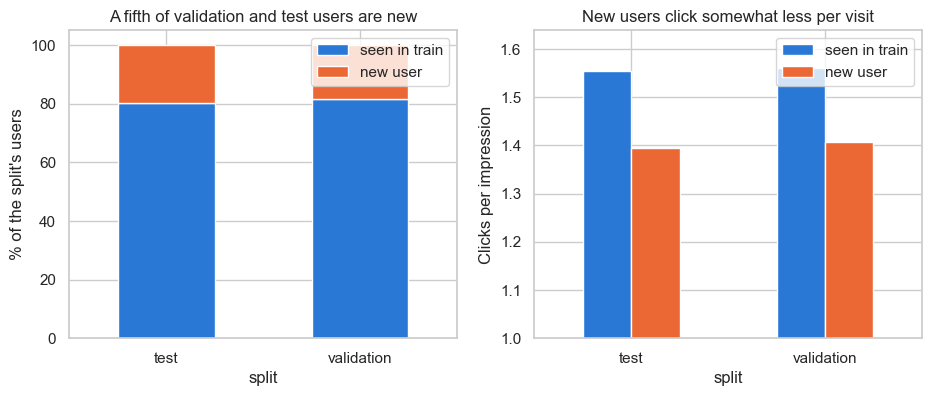

In [4]:
no_hist = imp.group_by(pl.col("history_len") == 0).agg(impressions=pl.len(), clicks_per_impression=pl.col("n_clicks").mean()).to_pandas()
no_hist.columns = ["no_history", "impressions", "clicks_per_impression"]
print(no_hist.round(3).to_string(index=False))

train_users = set(imp["user_code"].unique().to_list())
rows = []
for split in ["validation", "test"]:
    d = pl.read_parquet(PROCESSED / f"impressions_{split}.parquet", columns=["user_code", "history_len", "n_clicks"])
    d = d.with_columns(new_user=~pl.col("user_code").is_in(list(train_users)))
    g = d.group_by("new_user").agg(users=pl.col("user_code").n_unique(), impressions=pl.len(),
                                   median_history=pl.col("history_len").median(), clicks_per_impression=pl.col("n_clicks").mean()).to_pandas()
    g["split"] = split
    g["user_share"] = 100 * g.users / g.users.sum()
    rows.append(g)
new_users = pd.concat(rows).sort_values(["split", "new_user"])
print("\nUsers in validation / test by whether they appear in train:")
print(new_users.round(2).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
piv = new_users.pivot(index="split", columns="new_user", values="user_share")
piv.plot(kind="bar", stacked=True, ax=ax[0], rot=0)
ax[0].legend(["seen in train", "new user"])
ax[0].set(ylabel="% of the split's users", title="A fifth of validation and test users are new")
new_users.pivot(index="split", columns="new_user", values="clicks_per_impression").plot(kind="bar", ax=ax[1], rot=0)
ax[1].legend(["seen in train", "new user"])
ax[1].set(ylim=(1, None), ylabel="Clicks per impression", title="New users click somewhat less per visit")
plt.savefig(FIG_DIR / "usr_02_cold_start_users.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. The supplied history is a frozen snapshot: in-window clicks can extend it

A user's `history` string is identical across all of their impressions and across splits, including the test release. So a returning user's
test-day history does **not** contain the clicks they made on 9 to 14 November, although those clicks are observed with labels.
* **85% of test users** (82% of validation users) have such clicks: a median of 4 per user, 23% more history in total.
* Inside the training window the same holds time-causally: 65% of impressions are preceded by an earlier click of the same user.

**Model Implications**
* Build the profile as **supplied history + in-window clicks strictly before the impression timestamp** (for the test day: all train and
  validation clicks of the user). This is leakage-free and shows the model the freshest interests.

In [5]:
static = imp.group_by("user_code").agg(n_imp=pl.len())
print("Users with > 1 impression:", int((static["n_imp"] > 1).sum()), "| users whose history changes between impressions: 0 (verified in 1_Data_Preparation)")

in_window = cand.filter(pl.col("clicked") == 1).group_by("user_code").len().rename({"len": "train_clicks"})
val_clicks = (pl.read_parquet(PROCESSED / "candidates_validation.parquet", columns=["user_code", "clicked"])
              .filter(pl.col("clicked") == 1).group_by("user_code").len().rename({"len": "val_clicks"}))
for split in ["validation", "test"]:
    u = pl.read_parquet(PROCESSED / f"impressions_{split}.parquet", columns=["user_code", "history_len"]).unique("user_code").join(in_window, on="user_code", how="left")
    u = u.join(val_clicks, on="user_code", how="left") if split == "test" else u.with_columns(val_clicks=pl.lit(0))
    u = u.with_columns(added=pl.col("train_clicks").fill_null(0) + pl.col("val_clicks").fill_null(0))
    has = u.filter(pl.col("added") > 0)
    print(f"\n{split}: {100 * len(has) / len(u):.1f}% of users have in-window clicks not in their history; "
          f"median {has['added'].median():.0f} added clicks (mean {has['added'].mean():.1f}); "
          f"+{100 * u['added'].sum() / u['history_len'].sum():.0f}% on top of the supplied history")

prior = (imp.sort("user_code", "timestamp").with_columns(prior=pl.col("n_clicks").cum_sum().over("user_code") - pl.col("n_clicks")))
print(f"\nTraining impressions preceded by at least one in-window click of the same user: {100 * (prior['prior'] > 0).mean():.1f}%")

Users with > 1 impression: 423559 | users whose history changes between impressions: 0 (verified in 1_Data_Preparation)

validation: 81.6% of users have in-window clicks not in their history; median 4 added clicks (mean 6.3); +19% on top of the supplied history

test: 84.7% of users have in-window clicks not in their history; median 4 added clicks (mean 7.0); +23% on top of the supplied history



Training impressions preceded by at least one in-window click of the same user: 64.8%


# 4. What histories contain

* The 12.9 M history entries (once per user) cover **79,056 distinct articles**, of which only 5,026 were ever candidates in the window:
  histories are older than the slates. A typical user's history spans 5 categories.
* Histories lean more to news and sports than the slates MSN served in the window.

**Model Implications**
* Content-based user profiles are feasible (every history article has a title and category) and necessary: an id-based item model would see
  almost none of the history articles as candidates. Multi-category histories argue for multi-interest representations.

/var/folders/kz/x1bqw4g54k9bxv6zd2qlrp500000gn/T/ipykernel_36217/3500812039.py:3: DeprecationWarning: In Polars 2.0, the default behavior for `empty_as_null` will change to `False`. To keep the current behavior, explicitly set `empty_as_null=True`.
  .select("user_code", "h").explode("h").drop_nulls("h").rename({"h": "news_code"}).join(cat_map, on="news_code", how="left"))


History entries (once per user): 12874380 | distinct articles: 79056 | of which shown in the window: 5026
Median categories per user history: 5.0



Category share (%) of history entries vs window exposures and clicks:
               history  exposures  clicks
category                                 
news              30.2       28.0    30.4
sports            13.9       10.4    12.3
lifestyle         10.7       10.9    10.7
tv                 7.7        4.2     6.2
finance            7.4        9.6     8.8
foodanddrink       5.3        6.1     4.5
health             4.9        5.3     4.5
movies             3.7        2.2     1.5
autos              3.6        4.6     3.2
entertainment      3.5        6.2     4.7
travel             3.2        5.2     3.4
music              2.6        4.3     6.5


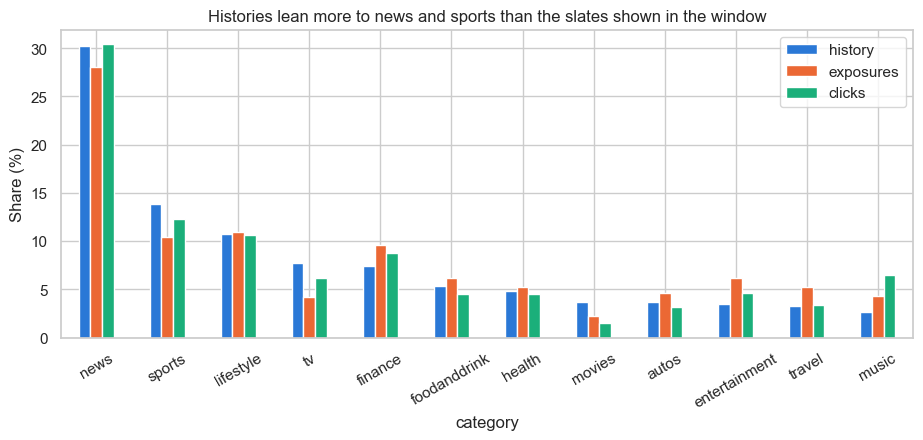

In [6]:
hist = (pl.read_parquet(PROCESSED / "impressions_train.parquet", columns=["user_code", "history"]).unique("user_code")
        .with_columns(h=pl.col("history").fill_null("").str.split(" ").list.eval(pl.element().filter(pl.element() != "").str.strip_prefix("N").cast(pl.Int32)))
        .select("user_code", "h").explode("h").drop_nulls("h").rename({"h": "news_code"}).join(cat_map, on="news_code", how="left"))
shown_in_window = hist.select("news_code").unique().join(news.filter(pl.col("exposures_train") > 0).select("news_code"), on="news_code").height
print("History entries (once per user):", len(hist), "| distinct articles:", hist["news_code"].n_unique(), "| of which shown in the window:", shown_in_window)
print("Median categories per user history:", hist.group_by("user_code").agg(pl.col("category").n_unique())["category"].median())

mix = (hist.group_by("category").len().rename({"len": "history"}).to_pandas().set_index("category"))
mix["history"] = 100 * mix.history / mix.history.sum()
exp = cand.join(cat_map, on="news_code").group_by("category").agg(exposures=pl.len(), clicks=pl.col("clicked").sum()).to_pandas().set_index("category")
mix["exposures"] = 100 * exp.exposures / exp.exposures.sum()
mix["clicks"] = 100 * exp.clicks / exp.clicks.sum()
mix = mix.sort_values("history", ascending=False).head(12)
print("\nCategory share (%) of history entries vs window exposures and clicks:")
print(mix.round(1))

mix.plot(kind="bar", figsize=(11, 4), rot=30)
plt.title("Histories lean more to news and sports than the slates shown in the window")
plt.ylabel("Share (%)")
plt.savefig(FIG_DIR / "usr_04_history_category_mix.png", dpi=150, bbox_inches="tight")
plt.show()
del hist

# 5. Does history-category affinity predict clicks?

For each impression we rebuild the user's category profile from the history: **affinity** = share of the user's past clicks in the candidate's
category. It uses only clicks before the window, so there is no target leakage.
* CTR rises monotonically from **2.9% at affinity 0 to 6.2% above 50%**, a 2.1× lift, and the gradient holds inside each of the four largest
  categories and on slates of length 50 to 100 (1.8% to 4.4%), so it is neither a category-mix nor a slate-size artefact.

**Model Implications**
* `category_affinity` is a strong, cheap, time-causal ranking feature. The lift is predictive, not causal: the existing recommender may already
  favour high-affinity items.

/var/folders/kz/x1bqw4g54k9bxv6zd2qlrp500000gn/T/ipykernel_36217/2451663743.py:3: DeprecationWarning: In Polars 2.0, the default behavior for `empty_as_null` will change to `False`. To keep the current behavior, explicitly set `empty_as_null=True`.
  .select("impression_uid", "h").explode("h").drop_nulls("h").rename({"h": "news_code"})


CTR (%) by affinity bin, all slates:
              exposures   ctr
affinity_bin                 
0              20776932  2.89
0-5%            7782390  2.98
5-10%           9123738  3.69
10-20%         12082010  4.40
20-30%          7024231  5.15
30-50%          8901958  5.83
>50%            4623128  6.21

CTR (%) by affinity bin, slates of length 50-100:
              exposures   ctr
affinity_bin                 
0               6879145  1.75
0-5%            2714649  2.18
5-10%           3175883  2.68
10-20%          4145673  3.17
20-30%          2380523  3.67
30-50%          2993169  4.04
>50%            1583310  4.38

CTR (%) by affinity bin within the four largest categories:
category      finance  lifestyle  news  sports
affinity_bin                                  
0                2.86       2.84  2.95    2.39
0-5%             2.92       2.25  1.73    1.88
5-10%            3.87       3.15  2.30    3.37
10-20%           4.63       4.46  3.27    5.30
20-30%           5.15       5

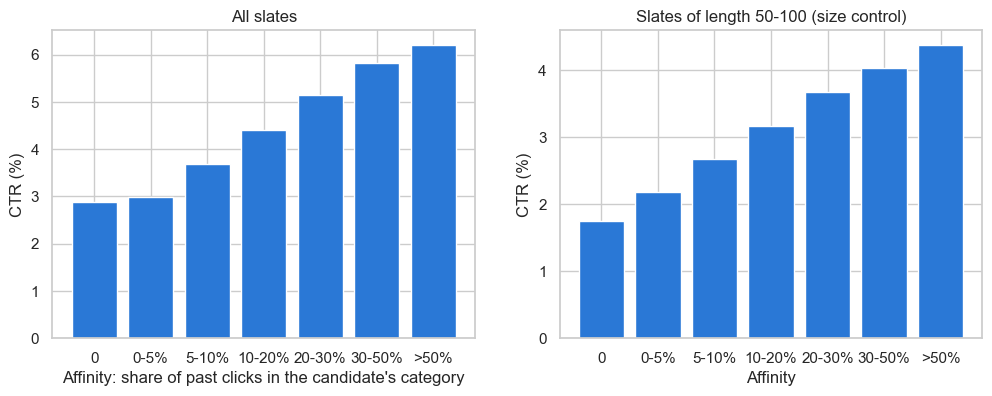

In [7]:
affinity = (pl.read_parquet(PROCESSED / "impressions_train.parquet", columns=["impression_uid", "history"])
            .with_columns(h=pl.col("history").fill_null("").str.split(" ").list.eval(pl.element().filter(pl.element() != "").str.strip_prefix("N").cast(pl.Int32)))
            .select("impression_uid", "h").explode("h").drop_nulls("h").rename({"h": "news_code"})
            .join(cat_map, on="news_code").group_by("impression_uid", "category").len()
            .with_columns(affinity=pl.col("len") / pl.col("len").sum().over("impression_uid")))
has_history = affinity.select("impression_uid").unique().with_columns(has_history=pl.lit(True))

cand_aff = (cand.join(cat_map, on="news_code").join(imp.select("impression_uid", "slate_len"), on="impression_uid")
            .join(affinity.select("impression_uid", "category", "affinity"), on=["impression_uid", "category"], how="left")
            .join(has_history, on="impression_uid", how="left")
            .with_columns(pl.col("affinity").fill_null(0.0), pl.col("has_history").fill_null(False)))
edges, labels = [0, 0.05, 0.1, 0.2, 0.3, 0.5], ["0", "0-5%", "5-10%", "10-20%", "20-30%", "30-50%", ">50%"]
cand_aff = cand_aff.with_columns(affinity_bin=pl.col("affinity").cut(edges, labels=labels, left_closed=False))

def ctr_table(df, keys):
    t = df.group_by(keys).agg(exposures=pl.len(), clicks=pl.col("clicked").sum()).to_pandas()
    t["ctr"] = 100 * t.clicks / t.exposures
    return t

all_slates = ctr_table(cand_aff, ["affinity_bin"]).set_index("affinity_bin").reindex(labels)
size_ctrl = ctr_table(cand_aff.filter(pl.col("slate_len").is_between(50, 100)), ["affinity_bin"]).set_index("affinity_bin").reindex(labels)
top4 = ["news", "lifestyle", "sports", "finance"]
by_cat = ctr_table(cand_aff.filter(pl.col("category").cast(pl.Utf8).is_in(top4)), ["category", "affinity_bin"])
by_cat["category"] = by_cat.category.astype(str)
print("CTR (%) by affinity bin, all slates:")
print(all_slates[["exposures", "ctr"]].round(2))
print("\nCTR (%) by affinity bin, slates of length 50-100:")
print(size_ctrl[["exposures", "ctr"]].round(2))
print("\nCTR (%) by affinity bin within the four largest categories:")
print(by_cat.pivot(index="affinity_bin", columns="category", values="ctr").reindex(labels).round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(labels, all_slates.ctr)
ax[0].set(xlabel="Affinity: share of past clicks in the candidate's category", ylabel="CTR (%)", title="All slates")
ax[1].bar(labels, size_ctrl.ctr)
ax[1].set(xlabel="Affinity", ylabel="CTR (%)", title="Slates of length 50-100 (size control)")
plt.savefig(FIG_DIR / "usr_05_affinity.png", dpi=150, bbox_inches="tight")
plt.show()

# 6. Novelty: does the category have to be in the history at all?

The affinity-0 bin mixes two situations: users with **no history** (cold users) and users whose history never touched the candidate's
category (**unseen category**).
* Seen-category candidates are clicked at **4.6%**, unseen-category candidates at **2.8%** (−39%), cold users at 4.1%; the ordering survives the
  size control. Unseen-category candidates are 19.4 M of 70.3 M exposures.

**Model Implications**
* History carries two distinct signals, intensity (affinity) and coverage (`seen_category`); keep both. Cold users behave like average users,
  so their fallback should be the population prior, not a pessimistic one.

All slates:
                 exposures   clicks   ctr
group                                    
cold user          1370904    56183  4.10
unseen category   19406028   544301  2.80
seen category     49537455  2268514  4.58

Slates of length 50-100:
                 exposures  clicks   ctr
group                                   
cold user           459026   13078  2.85
unseen category    6420119  107599  1.68
seen category     16993207  553593  3.26


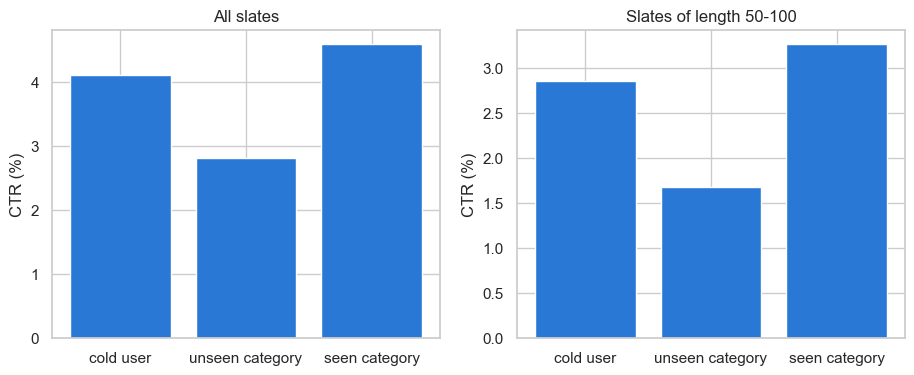

In [8]:
group = (pl.when(~pl.col("has_history")).then(pl.lit("cold user")).when(pl.col("affinity") == 0).then(pl.lit("unseen category")).otherwise(pl.lit("seen category")))
order = ["cold user", "unseen category", "seen category"]
nov = ctr_table(cand_aff.with_columns(group.alias("group")), ["group"]).set_index("group").reindex(order)
nov_ctrl = ctr_table(cand_aff.filter(pl.col("slate_len").is_between(50, 100)).with_columns(group.alias("group")), ["group"]).set_index("group").reindex(order)
print("All slates:")
print(nov.round(2))
print("\nSlates of length 50-100:")
print(nov_ctrl.round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(order, nov.ctr)
ax[0].set(ylabel="CTR (%)", title="All slates")
ax[1].bar(order, nov_ctrl.ctr)
ax[1].set(ylabel="CTR (%)", title="Slates of length 50-100")
plt.savefig(FIG_DIR / "usr_06_novelty.png", dpi=150, bbox_inches="tight")
plt.show()
del cand_aff

# 7. Time since the previous visit: short-term carry-over vs long-term preference

For users with at least three impressions, each impression with a gap is compared with the categories clicked in the user's **previous
impression** (short-term context) and with the user's **most-clicked category** over the window (long-term).
* 27 to 29% of a visit's clicks repeat a category from the previous visit, almost regardless of the gap; the share of clicks in the user's
  top category rises from 41% to 48% as the gap grows. Within users the movements are at most ±1.5 points, so most of the raw gradient is
  composition (users who return after long gaps have more concentrated tastes).

**Model Implications**
* Keep a recent component (last visit's clicks) next to the long-term profile; the gap itself is a weak switch between them.

Users with >= 3 impressions: 260,920; impressions with a gap: 1,067,316

Share of the visit's clicks (%) that repeat the previous visit's category / fall in the user's top category:
            prev_hit  top_hit
gap                          
<1 hour         26.9     41.7
1-6 hours       27.9     40.7
6-24 hours      28.7     45.1
1-3 days        28.3     46.4
>3 days         26.5     48.0

Within-user demeaned (percentage points):
            prev_hit  top_hit
gap                          
<1 hour        -0.10    -0.28
1-6 hours       0.06    -1.45
6-24 hours     -0.03     1.09
1-3 days        0.11     0.34
>3 days        -1.03    -0.47


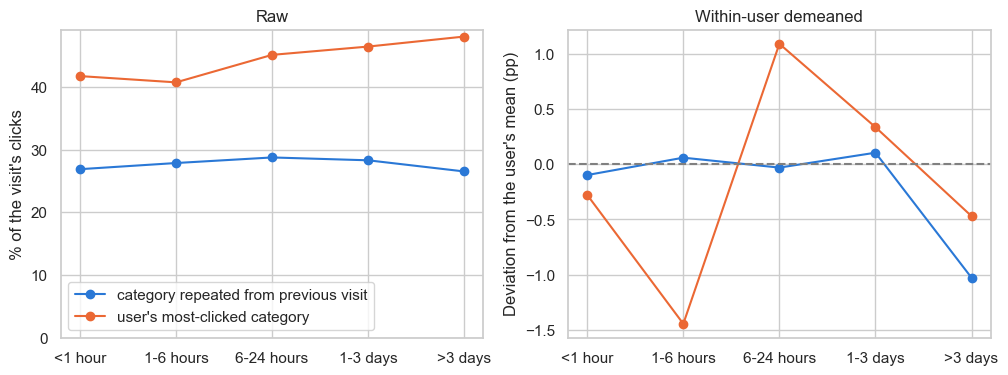

In [9]:
GAPS = ["<1 hour", "1-6 hours", "6-24 hours", "1-3 days", ">3 days"]
sess = (imp.select("impression_uid", "user_code", "timestamp").sort("user_code", "timestamp")
        .with_columns(gap_h=pl.col("timestamp").diff().over("user_code").dt.total_seconds() / 3600,
                      prev_uid=pl.col("impression_uid").shift(1).over("user_code"), n=pl.len().over("user_code"))
        .filter((pl.col("n") >= 3) & pl.col("gap_h").is_not_null())
        .with_columns(gap=pl.col("gap_h").cut([1, 6, 24, 72], labels=GAPS)))
clicks = cand.filter(pl.col("clicked") == 1).join(cat_map, on="news_code").select("impression_uid", "user_code", "category")
prev_cats = clicks.select(pl.col("impression_uid").alias("prev_uid"), "category").unique().with_columns(in_prev=pl.lit(True))
top_cat = (clicks.group_by("user_code", "category").len().sort("len", descending=True).unique("user_code", keep="first")
           .select("user_code", "category").with_columns(in_top=pl.lit(True)))
m = (clicks.join(sess.select("impression_uid", "gap", "prev_uid"), on="impression_uid")
     .join(prev_cats, on=["prev_uid", "category"], how="left").join(top_cat, on=["user_code", "category"], how="left")
     .with_columns(pl.col("in_prev").fill_null(False), pl.col("in_top").fill_null(False))
     .group_by("impression_uid", "user_code", "gap").agg(prev_hit=pl.col("in_prev").mean(), top_hit=pl.col("in_top").mean()))
raw = m.group_by("gap").agg(sessions=pl.len(), prev_hit=pl.col("prev_hit").mean(), top_hit=pl.col("top_hit").mean()).to_pandas().set_index("gap").reindex(GAPS)
dem = (m.with_columns(prev_hit=pl.col("prev_hit") - pl.col("prev_hit").mean().over("user_code"), top_hit=pl.col("top_hit") - pl.col("top_hit").mean().over("user_code"))
       .group_by("gap").agg(prev_hit=pl.col("prev_hit").mean(), top_hit=pl.col("top_hit").mean()).to_pandas().set_index("gap").reindex(GAPS))
print(f"Users with >= 3 impressions: {m['user_code'].n_unique():,}; impressions with a gap: {len(m):,}")
print("\nShare of the visit's clicks (%) that repeat the previous visit's category / fall in the user's top category:")
print((100 * raw[["prev_hit", "top_hit"]]).round(1))
print("\nWithin-user demeaned (percentage points):")
print((100 * dem).round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for col, lab in [("prev_hit", "category repeated from previous visit"), ("top_hit", "user's most-clicked category")]:
    ax[0].plot(GAPS, 100 * raw[col], marker="o", label=lab)
    ax[1].plot(GAPS, 100 * dem[col], marker="o", label=lab)
ax[0].set(ylim=(0, None), ylabel="% of the visit's clicks", title="Raw")
ax[0].legend()
ax[1].axhline(0, color="grey", ls="--")
ax[1].set(ylabel="Deviation from the user's mean (pp)", title="Within-user demeaned")
plt.savefig(FIG_DIR / "usr_07_short_vs_long_term.png", dpi=150, bbox_inches="tight")
plt.show()

# Summary

| Finding | Decision |
|---|---|
| Median user has 2 impressions; history median 11 per user, p95 64 | history cap ≈ 50; rely on history + content |
| 2% of impressions have no history; 18–20% of validation / test users are new | content-based profiles; explicit no-history fallback; report new vs returning users |
| Histories are frozen snapshots; 85% of test users have labelled in-window clicks | profile = supplied history + in-window clicks before the impression time |
| History articles mostly never appear as candidates; ~5 categories per user | content is the bridge; multi-interest representation |
| Affinity lifts CTR 2.1×, robust to category and slate size | `category_affinity` feature |
| Unseen category −39% CTR; cold users ≈ average | `seen_category` flag; population prior for cold users |
| Long-term alignment grows with the gap; within-user effects ±1.5 pp | recent + long-term components; gap is a weak switch |